# DPDP clause classifier: retraining walkthrough

Run **one cell at a time** (Shift+Enter) and read the output before moving on.

**Rule for this notebook:** the locked test set is only touched in Step 12, and only if you set `SCORE_TEST = True`. Everything before that uses cross-validation grouped by company, so no clause from the same policy is ever on both sides of a split.

Steps: 1 setup · 2 load · 3 class balance · 4 clean · 5 mix old `none` clauses · 6 clause lengths · 7 top words · 8 cross-validation · 9 per-class results · 10 read the errors · 11 final fit · 12 locked test (second round) · 13 save results.

## Step 1: setup
Edit the paths to match your repo. Leave `OLD_TRAIN` and `TEST` as `None` until you have exported those CSVs.

In [1]:
from pathlib import Path
import re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity
try:
    from IPython.display import display
except ImportError:
    display = print

# ---- edit these ----
SHEET = next(Path(r"F:\dpdp-classifier").rglob("privacy_clauses_dataset.csv"))  # .csv or .xlsx
OLD_TRAIN = None          # e.g. Path("data/old_train.csv")  columns: clause_text, obligation, policy_id
TEST = Path(r"F:\dpdp-classifier\data\test.csv")               # e.g. Path("data/test.csv")       columns: clause_text, obligation
TARGET = "obligation"     # "obligation" or "status"  (status labels are provisional, review them first)
OLD_NONE_N = 150          # how many old 'none' clauses to mix in
KEEP_TESTBOOK = False     # Testbook rows are paraphrases, not verbatim
USE_SYNTHETIC = True      # synthetic clauses are used for TRAINING only, never for validation
SCORE_TEST = True        # keep False until you are ready to score the locked test set ONCE
ROUND_ONE = {"svm": 0.623, "rf": 0.557, "keyword": 0.588}   # obligation macro-F1 from round one
OUT = Path("runs/retrain_walkthrough"); OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
print("sheet exists:", SHEET.exists())

sheet exists: True


## Step 2: load the sheet
Company name and id are only filled on the first row of each company, so we forward-fill them.

In [2]:
def read_any(p):
    p = Path(p)
    if p.suffix.lower() == ".csv":
        return pd.read_csv(p, keep_default_na=False, na_values=[""])      # keeps 'n/a' as text
    return pd.read_excel(p, sheet_name=0, keep_default_na=False, na_values=[""])

raw = read_any(SHEET).rename(columns={"clause": "clause_text"})
cid = raw["clause_id"].astype(str)
origin = raw["clause_origin"].astype(str).str.lower() if "clause_origin" in raw.columns else ""
raw["is_synth"] = (origin == "synthetic") | cid.str.startswith("SYN-")
raw["company"] = None
real = ~raw["is_synth"]
raw.loc[real, "company"] = raw.loc[real, "company_name"].ffill()    # company name is only on the first row
raw.loc[raw["is_synth"], "company"] = "Synthetic"
print(raw.shape, "| synthetic rows:", int(raw["is_synth"].sum()))
display(raw[["company", "clause_id", "label", "secondary_label", "dpdp_status", "is_synth"]].head(6))

(925, 11) | synthetic rows: 133


,company,clause_id,label,secondary_label,dpdp_status,is_synth
0,byjus,byjus_01,notice,NaN,satisfied,False
1,byjus,byjus_02,notice,NaN,satisfied,False
2,byjus,byjus_03,notice,NaN,satisfied,False
3,byjus,byjus_04,consent,NaN,satisfied,False
4,byjus,byjus_05,consent,NaN,not_satisfied,False
5,byjus,byjus_06,consent,NaN,not_satisfied,False


## Step 3: class balance
Look for thin classes. A class with very few examples cannot be learned or evaluated reliably.

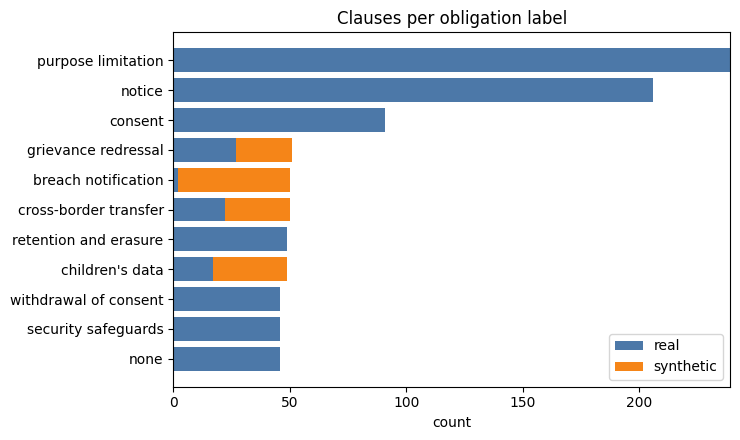

Fewer than 10 REAL examples (scores for these cannot be trusted): {'breach notification': np.int64(2)}


In [37]:
lab = raw.dropna(subset=["label"]).copy()
lab["label"] = lab["label"].astype(str).str.strip().str.lower().replace({"puprose limitation": "purpose limitation"})
tab = pd.crosstab(lab["label"], np.where(lab["is_synth"], "synthetic", "real"))
for c in ("real", "synthetic"):
    if c not in tab.columns: tab[c] = 0
tab = tab.loc[tab.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(tab.index, tab["real"], color="#4C78A8", label="real")
ax.barh(tab.index, tab["synthetic"], left=tab["real"], color="#F58518", label="synthetic")
ax.set_title("Clauses per obligation label"); ax.set_xlabel("count"); ax.legend()
plt.tight_layout(); plt.show()
thin = tab[tab["real"] < 10]["real"]
print("Fewer than 10 REAL examples (scores for these cannot be trusted):", dict(thin))

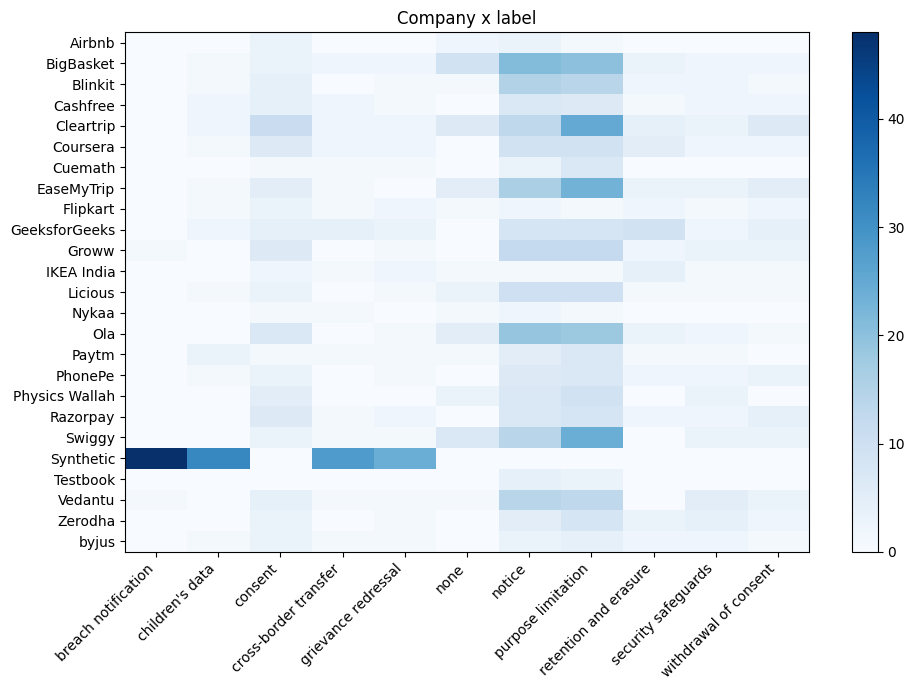

In [38]:
# which companies supply which labels (darker = more clauses)
tab = pd.crosstab(lab["company"], lab["label"])   # all companies, "Synthetic" included
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(tab.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns, rotation=45, ha="right")
ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
ax.set_title("Company x label"); plt.colorbar(im); plt.tight_layout(); plt.show()

## Step 4: clean
Drop empty or unlabelled rows, fix the `puprose` typo, remove exact duplicate text, and (by default) leave out the paraphrased Testbook rows. For `TARGET = "status"` only `satisfied` / `not_satisfied` rows are kept.

In [39]:
def norm_text(t): return re.sub(r"\s+", " ", str(t)).strip()

d = raw.copy()
n_start = len(d)
bad = d[d["clause_text"].isna() | d["label"].isna()]
print("rows with no clause text or no label (dropped, fix them in the sheet):", [str(x) for x in bad["clause_id"]])
d = d.dropna(subset=["clause_text", "label"])
n_labelled = len(d)
d["clause_text"] = d["clause_text"].map(norm_text)
d["label"] = d["label"].astype(str).str.strip().str.lower().replace({"puprose limitation": "purpose limitation"})
d["dpdp_status"] = d["dpdp_status"].astype(str).str.strip().str.lower().replace({"satiesfied": "satisfied"})
if not KEEP_TESTBOOK:
    d = d[d["company"].astype(str).str.lower() != "testbook"]
if not USE_SYNTHETIC:
    d = d[~d["is_synth"]]
n_after_tb = len(d)
if TARGET == "status":
    d = d[d["dpdp_status"].isin(["satisfied", "not_satisfied"])]
    d["y"] = d["dpdp_status"]
else:
    d["y"] = d["label"]
n_before_dup = len(d)
d = d.drop_duplicates(subset="clause_text")
d["group"] = d["company"].astype(str)
train = d[["clause_text", "y", "group", "is_synth"]].reset_index(drop=True)
summary = pd.DataFrame({"step": ["rows in file", "with text and label", "after Testbook/synthetic filter",
                                 "before dedupe", "final training rows"],
                        "rows": [n_start, n_labelled, n_after_tb, n_before_dup, len(train)]})
display(summary)
display(pd.crosstab(train["y"], np.where(train["is_synth"], "synthetic", "real")))

rows with no clause text or no label (dropped, fix them in the sheet): ['nan', 'SYN-CD-NS-002']


,step,rows
0,rows in file,925
1,with text and label,923
2,after Testbook/synthetic filter,916
3,before dedupe,916
4,final training rows,914


col_0,real,synthetic
y,,
breach notification,2,48
children's data,17,32
consent,91,0
cross-border transfer,22,28
grievance redressal,27,24
none,46,0
notice,201,0
purpose limitation,235,0
retention and erasure,49,0


## Step 5 (optional): mix in old `none` clauses
The new sheet has few `none` clauses (your test set was about 47% `none`). Export old training clauses to a CSV with columns `clause_text`, `obligation`, `policy_id`, then set `OLD_TRAIN` in Step 1. Skipped if `OLD_TRAIN` is `None`.

In [40]:
old_lengths = None
if OLD_TRAIN is not None and TARGET == "obligation":
    old = pd.read_csv(OLD_TRAIN)
    old["clause_text"] = old["clause_text"].map(norm_text)
    old["y"] = old["obligation"].astype(str).str.strip().str.lower()
    old["group"] = "old_" + (old["policy_id"].astype(str) if "policy_id" in old.columns else "x")
    old["is_synth"] = False
    old_lengths = old["clause_text"].str.split().str.len()
    none = old[old["y"] == "none"]
    keep = none.sample(n=min(OLD_NONE_N, len(none)), random_state=SEED)
    train = pd.concat([train, keep[["clause_text", "y", "group", "is_synth"]]], ignore_index=True)
    print(f"mixed in {len(keep)} old 'none' clauses")
else:
    print("no old clauses mixed in")
display(train["y"].value_counts().to_frame("count"))

no old clauses mixed in


,count
y,
purpose limitation,235
notice,201
consent,91
grievance redressal,51
cross-border transfer,50
breach notification,50
retention and erasure,49
children's data,49
withdrawal of consent,46


## Step 6: clause lengths
If your test clauses come from the automatic splitter and these are hand-extracted, the length distributions can differ. A big gap is an early warning of distribution shift.

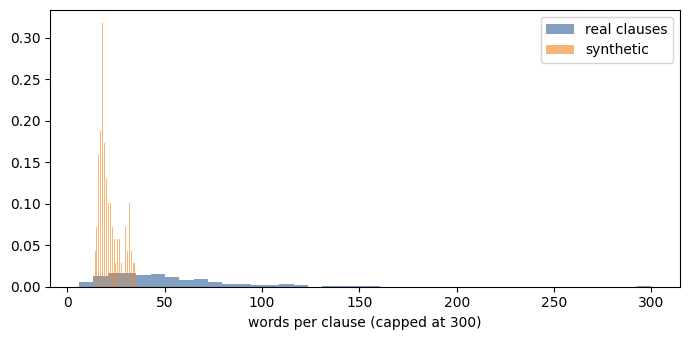

median words, real: 45 | synthetic: 19
Synthetic clauses are much shorter and more uniform than real ones; the model can learn length/phrasing shortcuts.


In [41]:
words = train["clause_text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(words[~train["is_synth"]].clip(upper=300), bins=40, alpha=0.7, label="real clauses", color="#4C78A8", density=True)
if train["is_synth"].any():
    ax.hist(words[train["is_synth"]].clip(upper=300), bins=40, alpha=0.6, label="synthetic", color="#F58518", density=True)
if old_lengths is not None:
    ax.hist(old_lengths.clip(upper=300), bins=40, alpha=0.4, label="old clauses", color="#54A24B", density=True)
ax.set_xlabel("words per clause (capped at 300)"); ax.legend(); plt.tight_layout(); plt.show()
print("median words, real:", int(words[~train["is_synth"]].median()),
      "| synthetic:", int(words[train["is_synth"]].median()) if train["is_synth"].any() else "n/a")
print("Synthetic clauses are much shorter and more uniform than real ones; the model can learn length/phrasing shortcuts.")

## Step 7: what words define each label?
A sanity check: the top words per label should make sense (for example `unsubscribe` for withdrawal, `grievance` for grievance redressal). Odd words can mean the model is learning company names instead of obligations.

In [42]:
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=8000)
Xall = vec.fit_transform(train["clause_text"])
terms = np.array(vec.get_feature_names_out())
overall = np.asarray(Xall.mean(axis=0)).ravel()
rows = {}
for lab_ in sorted(train["y"].unique()):
    m = (train["y"] == lab_).values
    diff = np.asarray(Xall[m].mean(axis=0)).ravel() - overall
    rows[lab_] = ", ".join(terms[np.argsort(diff)[::-1][:8]])
display(pd.DataFrame({"top terms": rows}))

,top terms
breach notification,"breach, affected, data breach, protection board, board, data, data protection, notify"
children's data,"children, parental, parental consent, age, child, children personal, consent, guardian"
consent,"consent, consent to, you, policy, agree, privacy policy, this, your consent"
cross-border transfer,"transfer, india, overseas, personal data, data, outside, transferred, international"
grievance redressal,"complaints, grievance, officer, grievances, com, contact, grievance officer, concerns"
none,"responsible for, responsible, privacy, not, shall, policy, not responsible, privacy policies"
notice,"collect, mobile, information, address, details, number, device, such as"
purpose limitation,"and, with, services, use, purposes, experience, and to, share"
retention and erasure,"retain, delete, deleted, longer, legal, retention, retain your, for"
security safeguards,"security, measures, secure, to protect, protect, security measures, measures to, industry"


## Step 8: cross-validation (grouped by company)
Five folds over the REAL clauses; each company lives in exactly one fold. Synthetic clauses are added to every training fold but are never used for validation. The chart compares training with and without them. Macro-F1 is computed only over the classes present in each fold's truth.

svm + synthetic: macro-F1 0.770 +/- 0.027
svm (real only): macro-F1 0.736 +/- 0.065
rf + synthetic: macro-F1 0.727 +/- 0.058
rf (real only): macro-F1 0.711 +/- 0.064


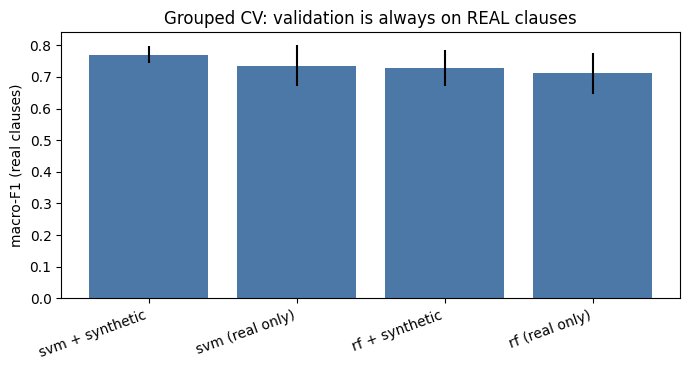

Synthetic clauses are only ever in the training folds. These CV numbers are NOT comparable with round-one test scores.


In [43]:
def make_models():
    tf = lambda: TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=8000)
    return {
        "svm": make_pipeline(tf(), LinearSVC(C=0.3, class_weight="balanced")),
        "rf": make_pipeline(tf(), RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_leaf=2,
                                class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    }

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)

X, y, g = train["clause_text"].values, train["y"].values, train["group"].values
syn_idx = np.where(train["is_synth"].values)[0]
real_idx = np.where(~train["is_synth"].values)[0]
gkf = GroupKFold(n_splits=min(5, len(set(g[real_idx]))))

def run_cv(name, use_syn=True):
    sc = []
    for tr, te in gkf.split(real_idx, y[real_idx], g[real_idx]):
        tr_idx = np.concatenate([real_idx[tr], syn_idx]) if use_syn else real_idx[tr]
        m = make_models()[name].fit(X[tr_idx], y[tr_idx])
        sc.append(macro_f1(y[real_idx[te]], m.predict(X[real_idx[te]])))
    return sc

fold_scores = {}
for name in make_models():
    for use_syn in ([True, False] if len(syn_idx) else [False]):
        key = f"{name}{' + synthetic' if use_syn else ' (real only)'}"
        fold_scores[key] = run_cv(name, use_syn)
        print(f"{key}: macro-F1 {np.mean(fold_scores[key]):.3f} +/- {np.std(fold_scores[key]):.3f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
keys = list(fold_scores)
ax.bar(range(len(keys)), [np.mean(fold_scores[k]) for k in keys], yerr=[np.std(fold_scores[k]) for k in keys], color="#4C78A8")
ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys, rotation=20, ha="right"); ax.set_ylabel("macro-F1 (real clauses)")
ax.set_title("Grouped CV: validation is always on REAL clauses"); plt.tight_layout(); plt.show()
print("Synthetic clauses are only ever in the training folds. These CV numbers are NOT comparable with round-one test scores.")

## Step 9: per-class results
One out-of-fold prediction per clause (each predicted by a model that never saw its company). Pick the model to inspect in `INSPECT`.

,precision,recall,f1-score,support
breach notification,1.000,1.000,1.000,2.000
children's data,0.889,0.941,0.914,17.000
consent,0.686,0.527,0.596,91.000
cross-border transfer,0.679,0.864,0.760,22.000
grievance redressal,0.862,0.926,0.893,27.000
none,0.719,0.500,0.590,46.000
notice,0.740,0.791,0.764,201.000
purpose limitation,0.772,0.736,0.754,235.000
retention and erasure,0.764,0.857,0.808,49.000
security safeguards,0.816,0.870,0.842,46.000


support = REAL clauses only; treat classes with support under 10 as unreliable.


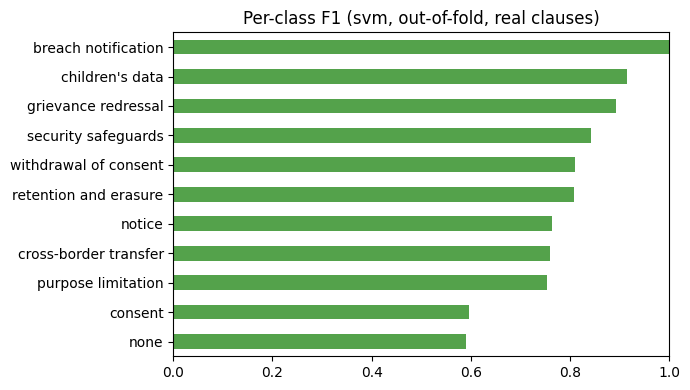

In [44]:
INSPECT = "svm"
pred = np.empty(len(train), dtype=object)
for tr, te in gkf.split(real_idx, y[real_idx], g[real_idx]):
    tr_idx = np.concatenate([real_idx[tr], syn_idx])
    m = make_models()[INSPECT].fit(X[tr_idx], y[tr_idx])
    pred[real_idx[te]] = m.predict(X[real_idx[te]])
yr, pr = y[real_idx], pred[real_idx].astype(str)
rep = pd.DataFrame(classification_report(yr, pr, zero_division=0, output_dict=True)).T
display(rep.round(3))
print("support = REAL clauses only; treat classes with support under 10 as unreliable.")
cls = [c for c in rep.index if c not in ("accuracy", "macro avg", "weighted avg")]
fig, ax = plt.subplots(figsize=(7, 4))
rep.loc[cls, "f1-score"].sort_values().plot.barh(ax=ax, color="#54A24B")
ax.set_xlim(0, 1); ax.set_title(f"Per-class F1 ({INSPECT}, out-of-fold, real clauses)"); plt.tight_layout(); plt.show()

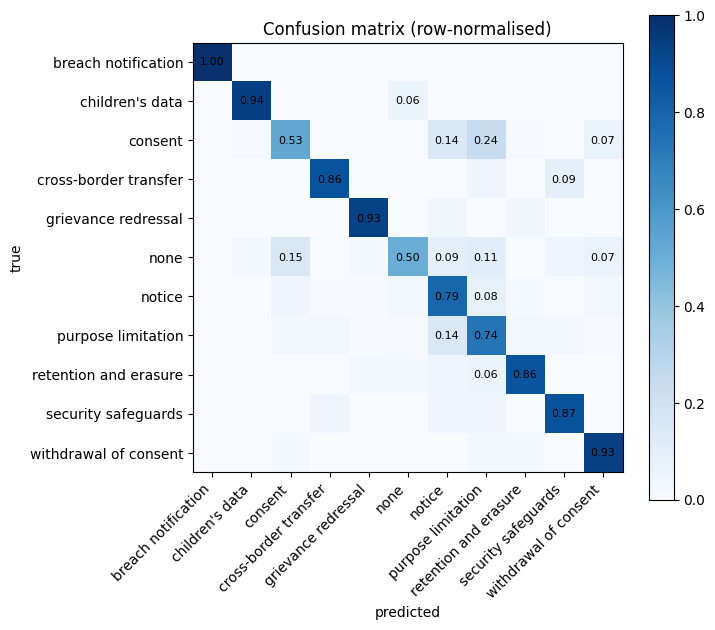

In [45]:
labels_sorted = sorted(np.unique(yr))
cm = confusion_matrix(yr, pr, labels=labels_sorted, normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels_sorted))); ax.set_xticklabels(labels_sorted, rotation=45, ha="right")
ax.set_yticks(range(len(labels_sorted))); ax.set_yticklabels(labels_sorted)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j] > 0.05: ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (row-normalised)")
plt.colorbar(im); plt.tight_layout(); plt.show()

## Step 10: read the errors
The most useful step. Skim the misclassified real clauses: are they label noise, genuine ambiguity, or something the model should have caught?

In [46]:
err = train.iloc[real_idx].assign(pred=pr)
err = err[err["y"] != err["pred"]]
print(f"{len(err)} wrong out of {len(real_idx)} real clauses")
pd.set_option("display.max_colwidth", 160)
display(err.sample(n=min(15, len(err)), random_state=SEED)[["group", "y", "pred", "clause_text"]])

192 wrong out of 782 real clauses


,group,y,pred,clause_text
193,Razorpay,consent,purpose limitation,We share this information with the respective businesses only if the customer consents to sharing it during transactions on Razorpay-powered applications.
578,Cleartrip,consent,retention and erasure,"You have given your consent (this legal basis is only used in relation to processing that is entirely voluntary, it is not used for processing that is neces..."
343,Groww,notice,none,"Our Platform may link You to other third – party Platforms (“Third – Party Sites”) that may collect Your Personal Information including Your IP address, bro..."
621,EaseMyTrip,notice,purpose limitation,"""Personal Information"" of User shall include the information shared by the User and collected by EaseMyTrip for the following purposes:"
485,BigBasket,purpose limitation,retention and erasure,"serve other purposes for which we provide specific notice at the time of collection, and as otherwise authorized or required by applicable law."
737,Flipkart,notice,consent,"When you use our Platform, we collect and store your information which is provided by you from time to time. Once you give us your personal data, you are no..."
55,Vedantu,consent,purpose limitation,"It is open for you to customize our usage of your personal information to communicate with you, to send you marketing information, how we provide you with c..."
67,Physics Wallah,notice,withdrawal of consent,If you choose to subscribe to any PW plan you may be required to upload a copy of a valid government issued identification document to allow access to the P...
59,Vedantu,none,consent,"You agree and acknowledge that Your right to access, modify and/or withdrawing Your consent to provide Personal Information as mentioned above may be denied..."
41,Vedantu,security safeguards,purpose limitation,"If you are an employee, vendor/supplier of Vedantu, your Personal Information may be shared internally with the relevant departments on a need-to-know basis."


## Step 11: final fit (no test set)
Train on all the training data and save both models. Nothing here touches the test set.

In [47]:
final = {}
for name, m in make_models().items():
    final[name] = m.fit(X, y)
    joblib.dump(m, OUT / f"{name}_{TARGET}_final.joblib")
print("saved models to", OUT.resolve())

saved models to F:\dpdp-classifier\notebooks\runs\retrain_walkthrough


## Step 12: locked test set (second round)

**Stop and check before running this cell.** The test set was scored once already. Scoring it again is a **second round**: report these numbers next to round one, never in place of them, and do not change settings after seeing them.

Set `TEST` in Step 1 (CSV with `clause_text`, `obligation`) and `SCORE_TEST = True`.

near-duplicates of test clauses removed from training: 0
svm {'macro_f1': 0.7778794928423763, 'acc': 0.7513513513513513}


,precision,recall,f1-score,support
breach notification,1.000,1.000,1.000,1.000
children's data,1.000,0.889,0.941,9.000
consent,0.833,0.600,0.698,25.000
cross-border transfer,1.000,0.833,0.909,12.000
grievance redressal,0.875,0.875,0.875,16.000
none,0.550,0.440,0.489,25.000
notice,0.364,0.500,0.421,8.000
purpose limitation,0.594,0.826,0.691,23.000
retention and erasure,0.909,0.800,0.851,25.000
security safeguards,0.952,0.870,0.909,23.000


rf {'macro_f1': 0.7004598162897181, 'acc': 0.7027027027027027}


,precision,recall,f1-score,support
breach notification,0.333,1.000,0.500,1.000
children's data,1.000,1.000,1.000,9.000
consent,0.625,0.600,0.612,25.000
cross-border transfer,0.769,0.833,0.800,12.000
grievance redressal,0.875,0.875,0.875,16.000
none,0.571,0.320,0.410,25.000
notice,0.385,0.625,0.476,8.000
purpose limitation,0.483,0.609,0.538,23.000
retention and erasure,0.900,0.720,0.800,25.000
security safeguards,0.905,0.826,0.864,23.000


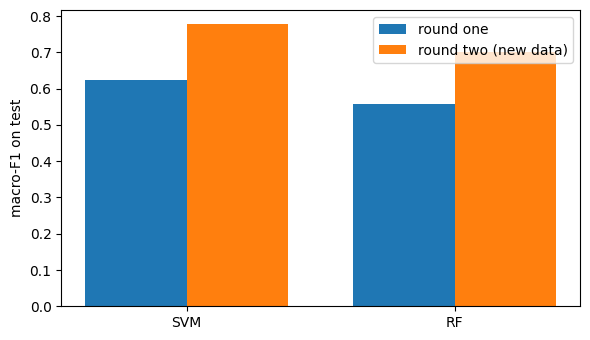

In [49]:
test_res = {}
if not (SCORE_TEST and TEST is not None):
    print("Skipped: set SCORE_TEST = True and TEST to a CSV path in Step 1 to run this.")
else:
    test = pd.read_csv(TEST)
    test["clause_text"] = test["clause_text"].map(norm_text)
    col = "obligation" if TARGET == "obligation" else "status"
    ytest = test[col].astype(str).str.strip().str.lower().values
    v = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(list(train["clause_text"]) + list(test["clause_text"]))
    sim = cosine_similarity(v.transform(train["clause_text"]), v.transform(test["clause_text"]))
    leak = sim.max(axis=1) >= 0.9
    print(f"near-duplicates of test clauses removed from training: {int(leak.sum())}")
    tr2 = train[~leak]
    for name, m in make_models().items():
        m.fit(tr2["clause_text"].values, tr2["y"].values)
        p = m.predict(test["clause_text"].values)
        test_res[name] = {"macro_f1": float(macro_f1(ytest, p)), "acc": float(accuracy_score(ytest, p))}
        print(name, test_res[name])
        display(pd.DataFrame(classification_report(ytest, p, zero_division=0, output_dict=True)).T.round(3))
    if TARGET == "obligation":
        fig, ax = plt.subplots(figsize=(6, 3.5))
        names = ["svm", "rf"]
        ax.bar(np.arange(2) - 0.19, [ROUND_ONE[n] for n in names], 0.38, label="round one")
        ax.bar(np.arange(2) + 0.19, [test_res[n]["macro_f1"] for n in names], 0.38, label="round two (new data)")
        ax.set_xticks(range(2)); ax.set_xticklabels(["SVM", "RF"]); ax.set_ylabel("macro-F1 on test")
        ax.legend(); plt.tight_layout(); plt.show()

## Step 13: save results
Writes a small JSON with the class counts, cross-validation scores and (if you ran Step 12) the round-two test scores.

In [50]:
result = {"target": TARGET, "class_counts": train["y"].value_counts().to_dict(),
          "cv_macro_f1": {k: {"mean": float(np.mean(v)), "sd": float(np.std(v))} for k, v in fold_scores.items()},
          "test_round2": test_res}
with open(OUT / f"results_{TARGET}.json", "w") as f: json.dump(result, f, indent=2)
print("saved", (OUT / f"results_{TARGET}.json").resolve())

saved F:\dpdp-classifier\notebooks\runs\retrain_walkthrough\results_obligation.json


In [17]:
import sqlite3
con = sqlite3.connect(r"F:\dpdp-classifier\db\dpdp.db")
for (t,) in con.execute("select name from sqlite_master where type='table'"):
    print(t, [c[1] for c in con.execute(f"pragma table_info({t})")])

policies ['policy_id', 'company_name', 'sector', 'source_url', 'status', 'status_note', 'date_accessed', 'content_hash', 'raw_path', 'split']
sqlite_sequence ['name', 'seq']
obligations ['obligation_id', 'name', 'act_section']
clauses ['clause_id', 'policy_id', 'clause_index', 'clause_text', 'text_hash', 'heading', 'flag']
annotations ['annotation_id', 'clause_id', 'annotator', 'obligation_id', 'status', 'created_at']
final_labels ['clause_id', 'obligation_id', 'status', 'method']
model_runs ['run_id', 'model_name', 'model_version', 'prompt_version', 'params_json', 'random_seed', 'started_at', 'notes']
predictions ['prediction_id', 'run_id', 'clause_id', 'predicted_obligation_id', 'predicted_status', 'confidence', 'latency_ms', 'raw_response']
evaluation_results ['eval_id', 'run_id', 'split', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'n_clauses', 'created_at']


In [18]:
import sqlite3, pandas as pd
con = sqlite3.connect(r"F:\dpdp-classifier\db\dpdp.db")
print(pd.read_sql("select split, count(*) n from policies group by split", con))

q = """
select c.clause_id, p.company_name, c.clause_text,
       o.name as obligation, f.status
from final_labels f
join clauses  c on c.clause_id  = f.clause_id
join policies p on p.policy_id  = c.policy_id
left join obligations o on o.obligation_id = f.obligation_id
where lower(p.split) = 'test'
"""
test = pd.read_sql(q, con)
test["obligation"] = (test["obligation"].fillna("none").str.strip().str.lower()
                      .replace({"childrens data": "children's data"}))
print(len(test))
print(test["obligation"].value_counts())
test.to_csv(r"F:\dpdp-classifier\data\test.csv", index=False)

   split    n
0   None  258
1   test   12
2  train   48
180
obligation
none                     85
purpose limitation       20
notice                   20
consent                  17
security safeguards      14
grievance redressal       8
retention and erasure     8
cross-border transfer     4
withdrawal of consent     4
Name: count, dtype: int64
